In [1]:
import pandas as pd
import numpy as np

In [20]:
# canada_df = pd.read_csv('../processed_data/applied_catalysis_canada_genders.csv')
# france_df = pd.read_csv('../processed_data/applied_catalysis_france_genders.csv')
# germany_df = pd.read_csv('../processed_data/applied_catalysis_germany_genders.csv')
# singapore_df = pd.read_csv('../processed_data/applied_catalysis_singapore_genders.csv')
# south_africa_df = pd.read_csv('../processed_data/applied_catalysis_south_africa_genders.csv')
# switzerland_df = pd.read_csv('../processed_data/applied_catalysis_switzerland_genders.csv')
# uk_df = pd.read_csv('../processed_data/applied_catalysis_uk_genders.csv')
# us_df = pd.read_csv('../processed_data/applied_catalysis_us_genders.csv')

canada_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_canada.csv')
france_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_france.csv')
germany_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_germany.csv')
singapore_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_singapore.csv')
south_africa_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_south_africa.csv')
switzerland_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_switzerland.csv')
uk_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_uk.csv')
us_df = pd.read_csv('../elsevier_data/solar_energy_materials_and_solar_cells_us.csv')


canada_df['Country'] = 'Canada'
france_df['Country'] = 'France'
germany_df['Country'] = 'Germany'
singapore_df['Country'] = 'Singapore'
south_africa_df['Country'] = 'South Africa'
switzerland_df['Country'] = 'Switzerland'
uk_df['Country'] = 'UK'
us_df['Country'] = 'United States'

# Combine all three dataframes into one
combined_df = pd.concat([canada_df, france_df, germany_df, singapore_df, south_africa_df, switzerland_df, uk_df, us_df], ignore_index=True)

# Check the combined dataframe
print(combined_df.head())


                                          Item Title  \
0  Distribution of impurity elements in slag–sili...   
1  Preparation of highly transparent conductive a...   
2  Thickness dependent enhanced efficiency of pol...   
3  Effects of annealing and degradation on regior...   
4  Exploiting aromaticity in fatty terephthalate ...   

                        Publication Title  Book Series Title  Journal Volume  \
0  Solar Energy Materials and Solar Cells                NaN            94.0   
1  Solar Energy Materials and Solar Cells                NaN           203.0   
2  Solar Energy Materials and Solar Cells                NaN           116.0   
3  Solar Energy Materials and Solar Cells                NaN            94.0   
4  Solar Energy Materials and Solar Cells                NaN           238.0   

   Journal Issue                      Item DOI  \
0           12.0  10.1016/j.solmat.2010.06.025   
1            NaN  10.1016/j.solmat.2019.110161   
2            NaN  10.1016/j.solm

In [30]:
combined_df.to_csv('../test.csv', index=False)

In [21]:
def count_authors_by_country(df):
    authors_by_country = {}
    all_authors = set()
    
    # Process each row in the dataframe
    for index, row in df.iterrows():
        country = row.get('Country')
        if pd.isna(country):
            country = 'Unknown'
        
        # Initialize empty set for this country if not already present
        if country not in authors_by_country:
            authors_by_country[country] = set()
        
        # Process first author if available
        if 'First Author' in df.columns and not pd.isna(row['First Author']):
            first_author = row['First Author'].strip()
            authors_by_country[country].add(first_author)
            all_authors.add(first_author)
        
        # Process additional authors if available
        if 'Authors' in df.columns and not pd.isna(row['Authors']):
            author_text = row['Authors']
            
            # Handle different possible formats of the authors column
            if isinstance(author_text, list):
                # If it's already a list
                for author in author_text:
                    if author.strip():  # Check if not empty
                        authors_by_country[country].add(author.strip())
                        all_authors.add(author.strip())
            else:
                # Assuming authors are comma-separated (adjust if using a different separator)
                try:
                    for author in author_text.split(','):
                        if author.strip():  # Check if not empty
                            authors_by_country[country].add(author.strip())
                            all_authors.add(author.strip())
                except:
                    # If splitting fails, add as is
                    if author_text.strip():
                        authors_by_country[country].add(author_text.strip())
                        all_authors.add(author_text.strip())
    
    authors_count_by_country = {country: len(authors) for country, authors in authors_by_country.items()}
    
    sorted_authors_by_country = dict(sorted(authors_count_by_country.items(), 
                                           key=lambda item: item[1], 
                                           reverse=True))
    
    return len(all_authors), sorted_authors_by_country


total_authors, authors_by_country = count_authors_by_country(combined_df)

print(f"Total number of unique authors across all countries: {total_authors}")
print("\nNumber of authors by country:")
for country, count in authors_by_country.items():
    print(f"{country}: {count}")

authors_series = pd.Series(authors_by_country)
print("\nTop 5 countries by number of authors:")
print(authors_series.head(5))

Total number of unique authors across all countries: 9100

Number of authors by country:
Germany: 3993
France: 2281
UK: 1280
United States: 979
Switzerland: 746
Singapore: 740
Canada: 586
South Africa: 108

Top 5 countries by number of authors:
Germany          3993
France           2281
UK               1280
United States     979
Switzerland       746
dtype: int64


In [8]:
combined_df.fillna('')

,Item Title,Publication Title,Journal Volume,Journal Issue,Item DOI,Keywords,Authors,Publication Year,URL,Content Type,...,Mentions,Social Media,Usages,Gender (First Author),Gender likelihood (First Author),Gender (Authors),Gender likelihood (Authors),Country,Gender (First Author).1,Gender likelihood (First Author).1
0,Improved carbon disulfide conversion: Modifica...,Applied Catalysis A: General,604.0,,10.1016/j.apcata.2020.117773,Claus catalyst; Alumina; Transition metal oxid...,"['Christopher B. Lavery', 'Connor E. Deering',...",2020.0,https://www.sciencedirect.com/science/article/...,Article,...,0.0,0.0,0.0,male,0.526893,"['male', 'female', 'female', 'female', 'female...","[0.633540375128249, 0.6008205505158888, 0.5369...",Canada,,
1,Stability of Mo2C/carbon catalysts during dibe...,Applied Catalysis A: General,600.0,,10.1016/j.apcata.2020.117628,Molybdenum carbide; Hydrodeoxygenation (HDO); ...,"['Haiyan Wang', 'Changsoo Kim', 'Kevin J. Smith']",2020.0,https://www.sciencedirect.com/science/article/...,Article,...,0.0,0.0,0.0,female,0.73519,"['male', 'female', 'female']","[0.532304565149329, 0.5350669063840109, 0.5671...",Canada,,
2,Bimetallic catalysts: Requirements for stabili...,Applied Catalysis A: General,482.0,,10.1016/j.apcata.2014.06.016,Core–shell; Stabilizer; Structure control; PVP...,['Natalia V. Semagina'],2014.0,https://www.sciencedirect.com/science/article/...,Article,...,0.0,0.0,0.0,male,0.930717,['female'],[0.684981447898624],Canada,,
3,Impacts of vanadium and coke deposits on the C...,Applied Catalysis A: General,504.0,,10.1016/j.apcata.2014.11.006,Gasification; Nickel; Vanadium; Coke; Petroleu...,['Josephine M. Hill'],2015.0,https://www.sciencedirect.com/science/article/...,Article,...,0.0,0.0,0.0,male,0.711212,['female'],[0.600962241557212],Canada,,
4,Synthesis and characterization of mesoporous a...,Applied Catalysis A: General,489.0,,10.1016/j.apcata.2014.10.008,Mesoporous aluminas; Hydrotreating; Hydrodesul...,"['Rajesh V. Sharma', 'Ajay K. Kumar Dalai', 'J...",2015.0,https://www.sciencedirect.com/science/article/...,Article,...,0.0,0.0,0.0,male,0.716764,"['female', 'female', 'female']","[0.5347053571969612, 0.6186904571020698, 0.536...",Canada,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1530,Efficient transformation in characteristics of...,Applied Catalysis A: General,544.0,,10.1016/j.apcata.2017.07.007,Chemical reduction; Solvo-thermal; Graphene su...,"['Muhammad Danish', 'Shuguang Lü', 'Mark L. Br...",2017.0,https://www.sciencedirect.com/science/article/...,Article,...,1.0,0.0,0.0,male,0.915423,,,United States,,
1531,Novel mesoporous TiO2(B) whisker-supported sul...,Applied Catalysis A: General,574.0,,10.1016/j.apcata.2019.01.025,TiO2(B); Sulfated solid superacid; Acid proper...,"['Hainqin Yue', 'Tuo Ji', 'Wei Li', 'Xuejuan Z...",2019.0,B,Article,...,0.0,0.0,0.0,male,0.631779,,,United States,,
1532,Catalytic conversion of syngas to mixed alcoho...,Applied Catalysis A: General,,,10.1016/j.apcata.2012.04.005,Mixed alcohols synthesis; Syngas; Zn-Mn promot...,"['Fei Yu', 'Jin Hu', 'Jian Liu']",2012.0,https://www.sciencedirect.com/science/article/...,Article,...,1.0,0.0,0.0,male,0.674415,,,United States,,
1533,Palladium (0) metal clusters: Novel Krebs type...,Applied Catalysis A: General,453.0,,10.1016/j.apcata.2012.12.045,Pd; Au and Ag metal-clusters; Polyoxoanions st...,"['Paul Ludwig Michael Noeske', 'Ryan Matthew R...",2013.0,0,Article,...,0.0,0.0,0.0,male,0.692368,,,United States,,


In [9]:
data = combined_df

In [10]:
data = data[(data['Publication Year'] >= 2010) & (data['Publication Year'] <= 2025)]

In [11]:
data = data.drop(data[data['Publication Title'] == 'Editor(s): Bent Sørensen'].index)

In [7]:
data.to_csv('C:/Users/aznur/Desktop/Projects/energy_insights/data/everything_uk_genders.csv', index = False)

In [9]:
data.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/everything_uk_genders.csv', index = False)

In [12]:
data.info()

data.describe()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1423 entries, 0 to 1534
Data columns (total 26 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Item Title                          1423 non-null   object 
 1   Publication Title                   1423 non-null   object 
 2   Journal Volume                      1288 non-null   float64
 3   Journal Issue                       33 non-null     object 
 4   Item DOI                            1423 non-null   object 
 5   Keywords                            1405 non-null   object 
 6   Authors                             1423 non-null   object 
 7   Publication Year                    1423 non-null   float64
 8   URL                                 1423 non-null   object 
 9   Content Type                        1423 non-null   object 
 10  Citations (Crossref)                1423 non-null   float64
 11  First Author                        1423 no

,Journal Volume,Publication Year,Citations (Crossref),First Author H-Index,Captures,Citations,Mentions,Social Media,Usages,Gender likelihood (First Author)
count,1288.000000,1423.000000,1423.000000,1423.000000,1423.00000,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000
mean,514.727484,2015.643710,34.260014,13.334505,39.22558,36.023190,0.035840,1.153197,4.561490,0.774570
std,89.695823,4.134378,53.840807,12.869211,51.13977,57.726051,0.200513,8.948540,27.765068,0.139510
min,372.000000,2010.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.524420
25%,452.000000,2012.000000,11.000000,4.000000,16.00000,12.000000,0.000000,0.000000,0.000000,0.680150
50%,510.000000,2015.000000,23.000000,9.000000,28.00000,23.000000,0.000000,0.000000,0.000000,0.767923
75%,583.000000,2019.000000,42.000000,18.000000,47.00000,43.000000,0.000000,0.000000,0.000000,0.904811
max,692.000000,2025.000000,1422.000000,93.000000,1223.00000,1550.000000,3.000000,146.000000,571.000000,0.986692


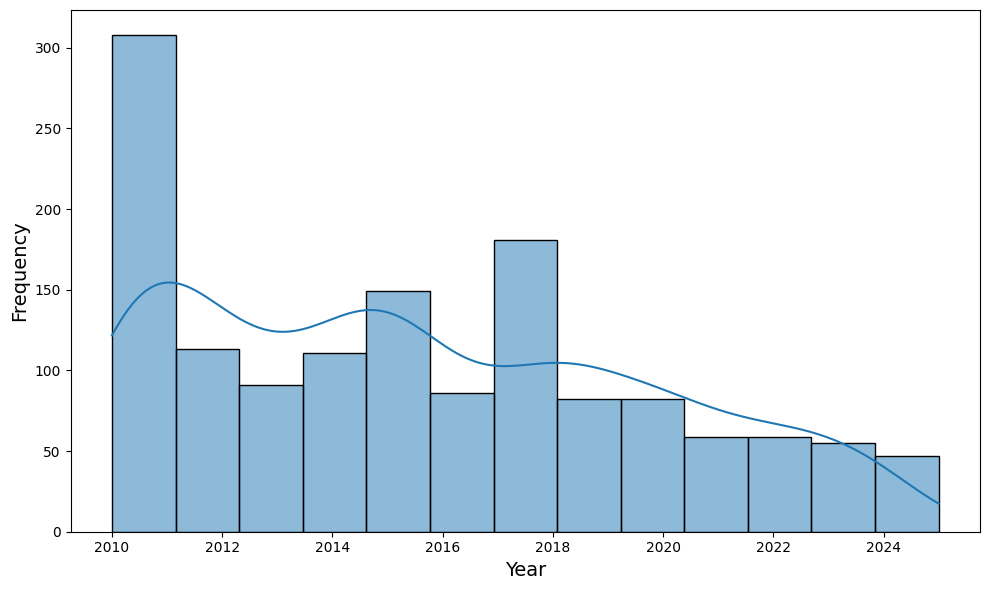

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6), dpi=100)
sns.histplot(data['Publication Year'], bins=13, kde=True)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.tight_layout()
plt.savefig('publications_distribution.png')
# plt.show()

In [14]:
data.columns

Index(['Item Title', 'Publication Title', 'Journal Volume', 'Journal Issue',
       'Item DOI', 'Keywords', 'Authors', 'Publication Year', 'URL',
       'Content Type', 'Citations (Crossref)', 'First Author',
       'First Author H-Index', 'Authors H-index', 'Captures', 'Citations',
       'Mentions', 'Social Media', 'Usages', 'Gender (First Author)',
       'Gender likelihood (First Author)', 'Gender (Authors)',
       'Gender likelihood (Authors)', 'Country', 'Gender (First Author).1',
       'Gender likelihood (First Author).1'],
      dtype='object')

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming you've already combined the datasets into combined_df
# First, let's count the number of publication titles per country
pub_count_per_country = combined_df['Country'].value_counts()

# For rough numbers of first authors who are female or male, let's count based on the 'Gender (First Author)' column
first_author_gender_count = combined_df.groupby('Country')['Gender (First Author)'].value_counts().unstack(fill_value=0)

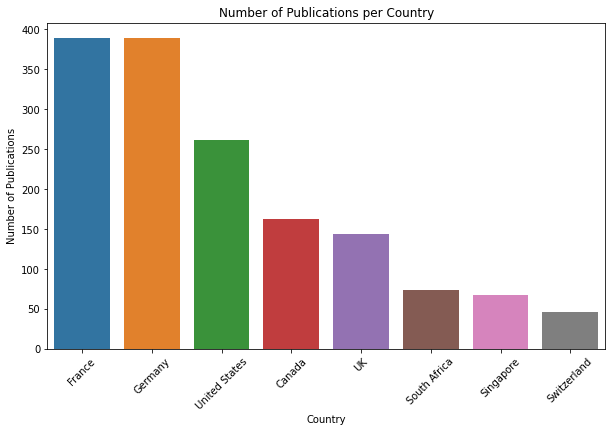

In [16]:
# Plot the number of publications per country
plt.figure(figsize=(10, 6))
sns.barplot(x=pub_count_per_country.index, y=pub_count_per_country.values)
plt.title('Number of Publications per Country')
plt.xlabel('Country')
plt.ylabel('Number of Publications')
plt.xticks(rotation=45)
plt.show()

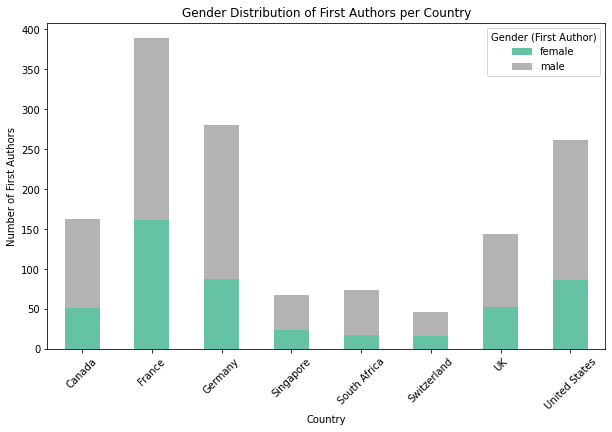

In [17]:
# Plot the gender distribution of first authors per country
first_author_gender_count.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title('Gender Distribution of First Authors per Country')
plt.xlabel('Country')
plt.ylabel('Number of First Authors')
plt.xticks(rotation=45)
plt.show()

In [18]:
# Output the counts for review
print("Number of Publications per Country:\n", pub_count_per_country)
print("\nGender Distribution of First Authors per Country:\n", first_author_gender_count)

Number of Publications per Country:
 France           389
Germany          389
United States    262
Canada           163
UK               144
South Africa      74
Singapore         68
Switzerland       46
Name: Country, dtype: int64

Gender Distribution of First Authors per Country:
 Gender (First Author)  female  male
Country                            
Canada                     51   112
France                    162   227
Germany                    87   194
Singapore                  24    44
South Africa               18    56
Switzerland                16    30
UK                         53    91
United States              86   176


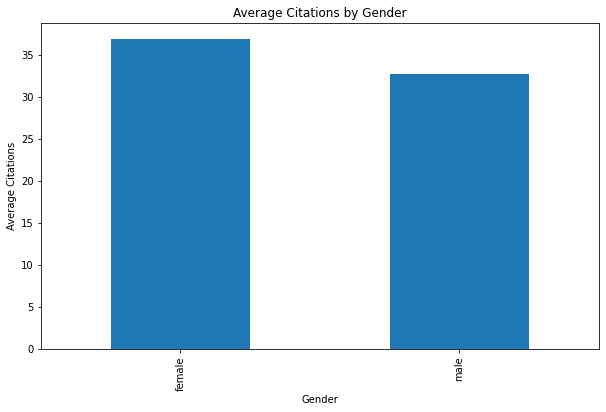

In [19]:
gender_citations = combined_df.groupby('Gender (First Author)')['Citations (Crossref)'].mean()
gender_citations.plot(kind='bar', figsize=(10, 6), title="Average Citations by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Citations")
plt.show()

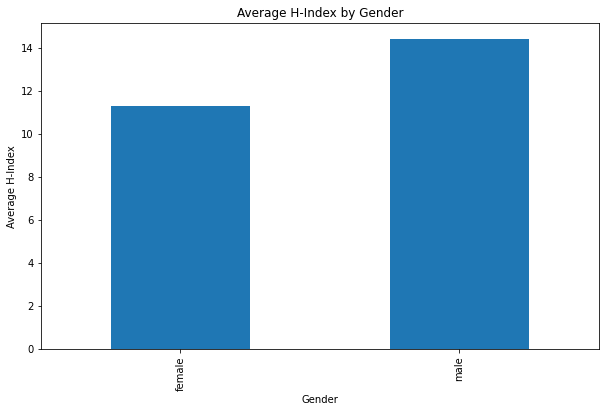

In [ ]:
gender_hindex = combined_df.groupby('Gender (First Author)')['First Author H-Index'].mean()
gender_hindex.plot(kind='bar', figsize=(10, 6), title="Average H-Index by Gender")
plt.xlabel("Gender")
plt.ylabel("Average H-Index")
plt.show()

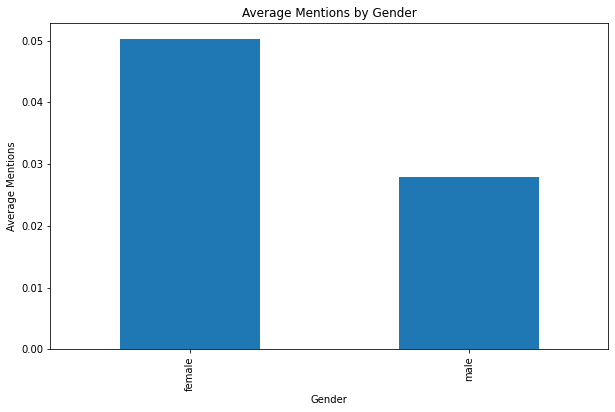

In [21]:
gender_mentions = combined_df.groupby('Gender (First Author)')['Mentions'].mean()
gender_mentions.plot(kind='bar', figsize=(10, 6), title="Average Mentions by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Mentions")
plt.show()

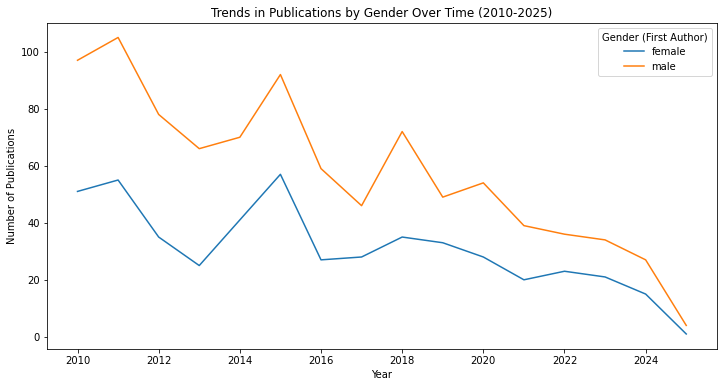

In [26]:
# Filter the data to include only years from 2010 to 2025
filtered_data = combined_df[(combined_df['Publication Year'] >= 2010) & (combined_df['Publication Year'] <= 2025)]

# Calculate the number of publications per gender and year
gender_yearly_trends = filtered_data.groupby(['Publication Year', 'Gender (First Author)'])['Item Title'].count().unstack(fill_value=0)

# Plot the data
gender_yearly_trends.plot(kind='line', figsize=(12, 6), title="Trends in Publications by Gender Over Time (2010-2025)")
plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.show()

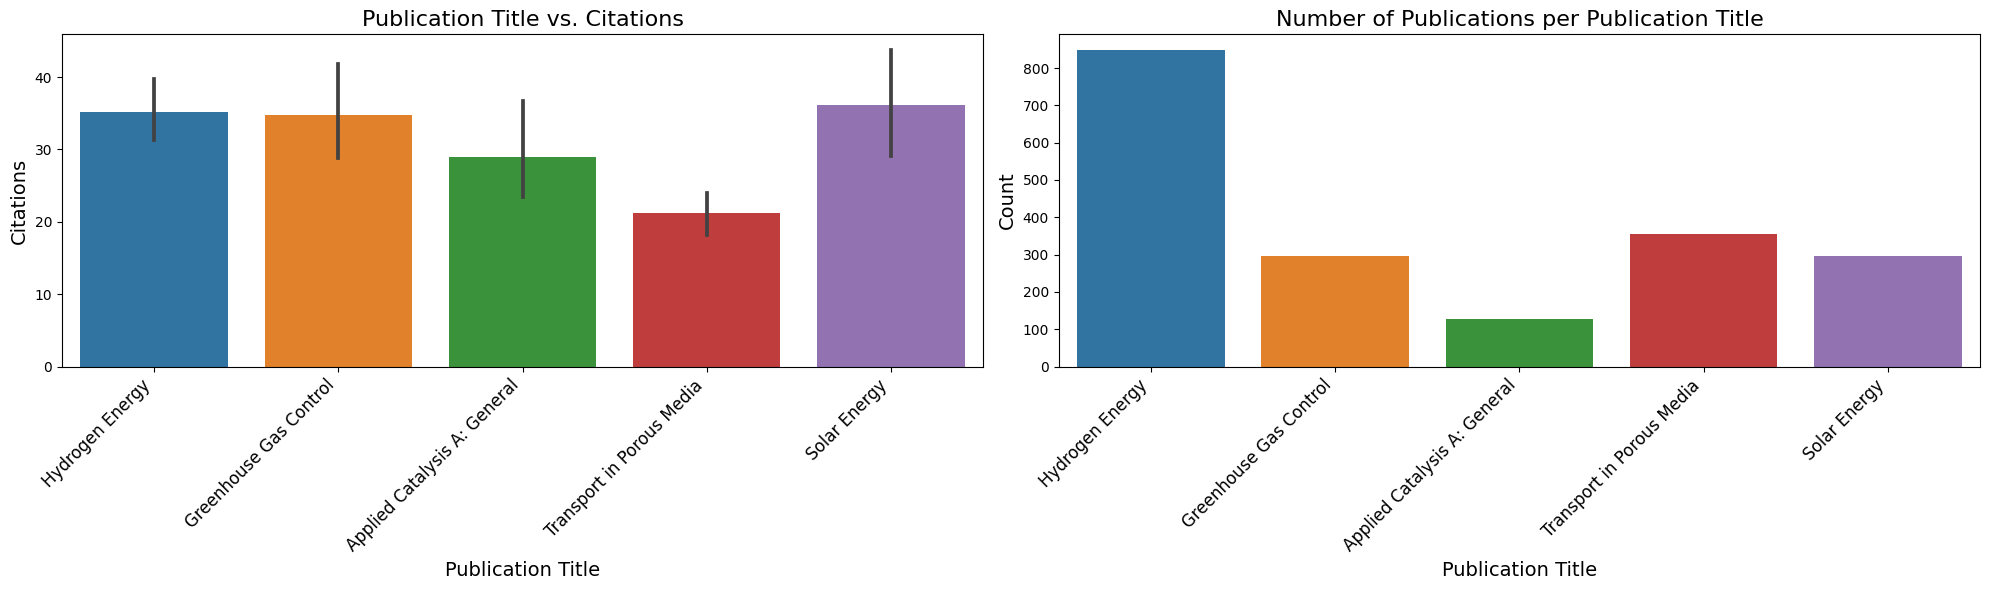

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), dpi=100)

sns.barplot(data=data, x='Publication Title', y='Citations', ax=ax1)
ax1.set_title('Publication Title vs. Citations', fontsize=16)

custom_xticks = [0, 1, 2, 3, 4]  
custom_xticklabels = ['Hydrogen Energy', 'Greenhouse Gas Control', 'Applied Catalysis A: General', 
                      'Transport in Porous Media', 'Solar Energy']  # Set the labels for the custom xticks
ax1.set_xticks(custom_xticks)
ax1.set_xticklabels(custom_xticklabels, rotation=45, ha='right', fontsize=12)

ax1.set_xlabel('Publication Title', fontsize=14)
ax1.set_ylabel('Citations', fontsize=14)

sns.countplot(data=data, x='Publication Title', ax=ax2)
ax2.set_title('Number of Publications per Publication Title', fontsize=16)

custom_xticks = [0, 1, 2, 3, 4]
custom_xticklabels = ['Hydrogen Energy', 'Greenhouse Gas Control', 'Applied Catalysis A: General', 
                      'Transport in Porous Media', 'Solar Energy']  # Set the labels for the custom xticks
ax2.set_xticks(custom_xticks)
ax2.set_xticklabels(custom_xticklabels, rotation=45, ha='right', fontsize=12)

ax2.set_xlabel('Publication Title', fontsize=14)
ax2.set_ylabel('Count', fontsize=14)

plt.tight_layout()

plt.savefig('combined_publications.png')

plt.show()

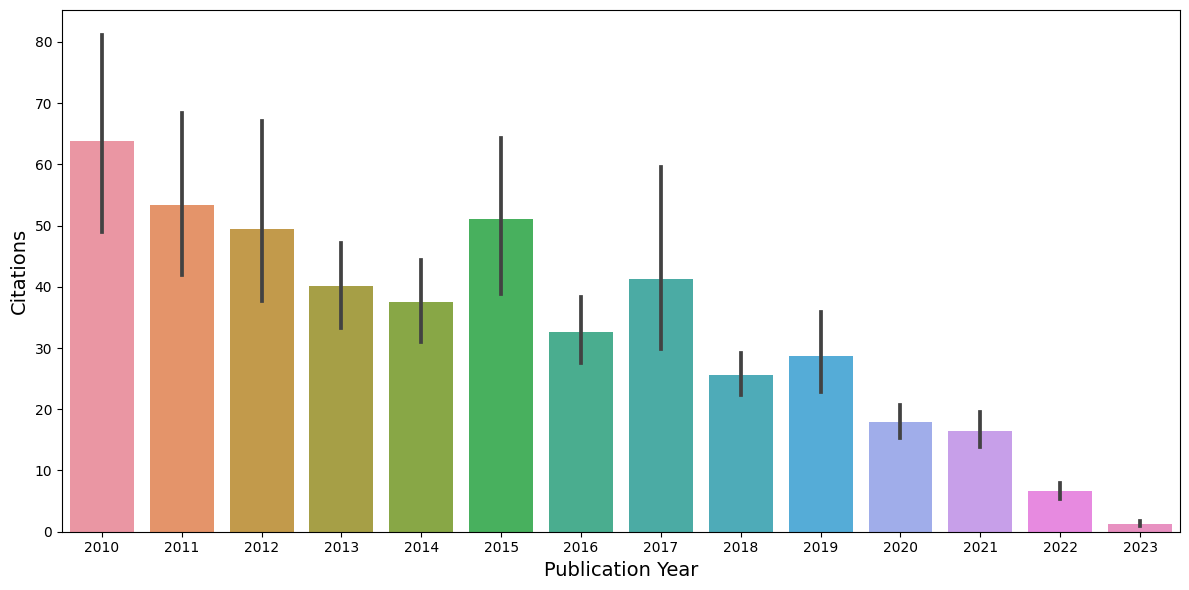

In [13]:
plt.figure(figsize=(12, 6), dpi=100)
sns.barplot(data=data, x='Publication Year', y='Citations')
plt.xlabel('Publication Year', fontsize=14)
plt.ylabel('Citations', fontsize=14)
plt.tight_layout()
plt.savefig('publications_vs_citations.png')
# plt.show()

C:\Users\aznur\AppData\Local\Temp/ipykernel_11988/3183084021.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = data.corr()


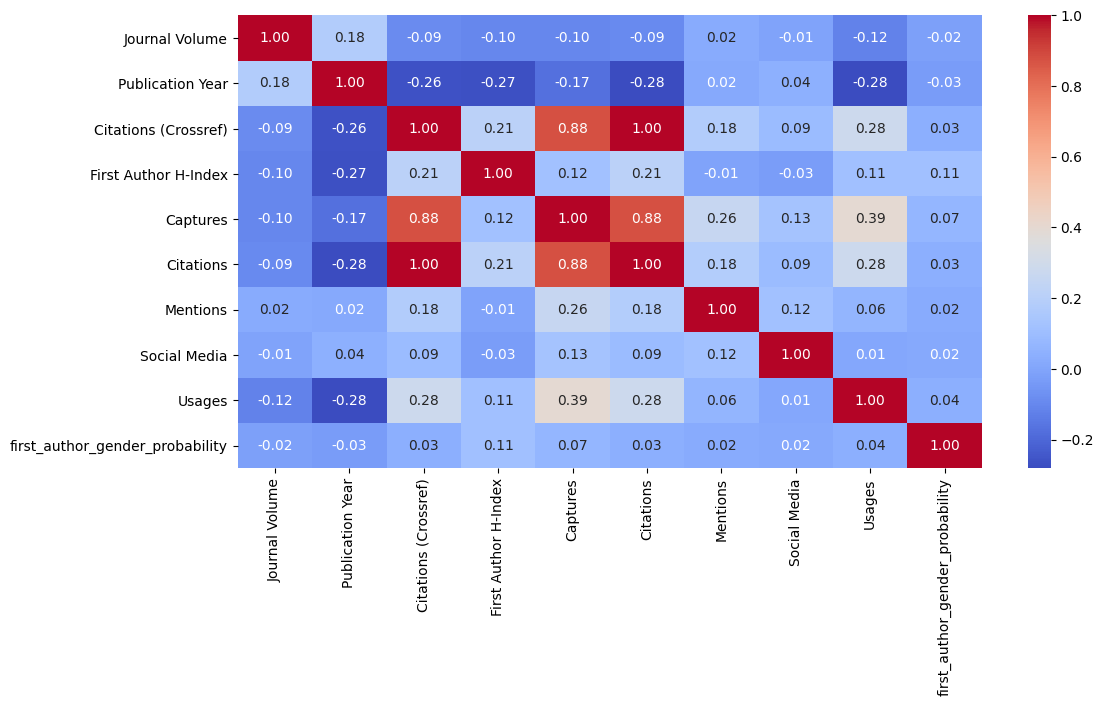

In [15]:
correlation_matrix = data.corr()

plt.figure(figsize=(12, 6), dpi=100)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

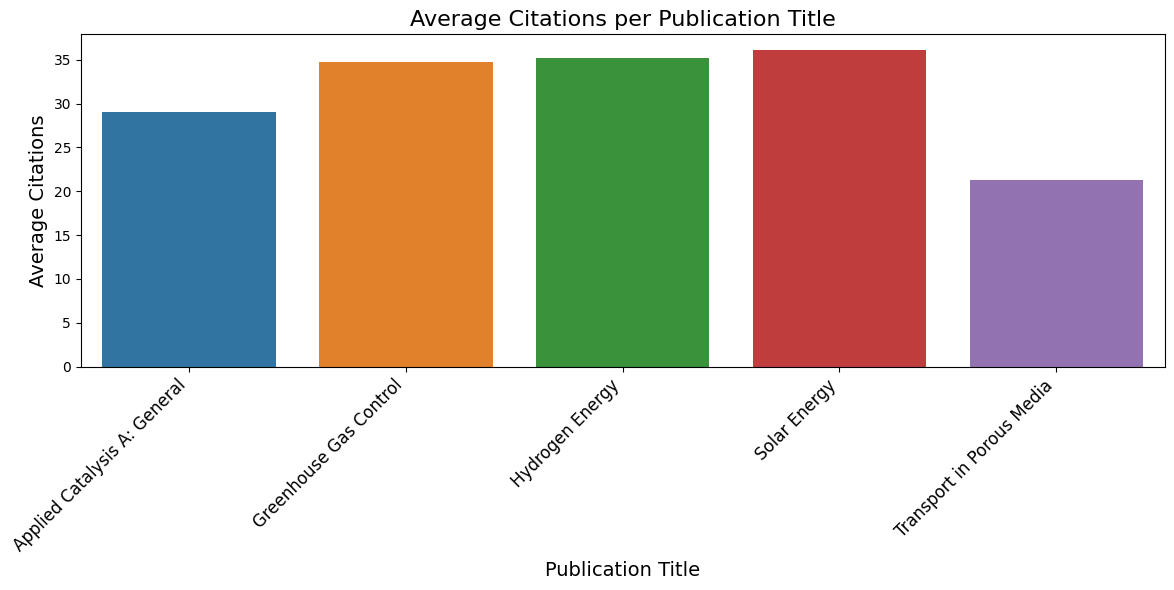

In [16]:
citation_by_publication = data.groupby('Publication Title')['Citations'].mean().reset_index()

plt.figure(figsize=(12, 6), dpi=100)
sns.barplot(data=citation_by_publication, x='Publication Title', y='Citations')
custom_xticks = [0, 1, 2, 3, 4]
custom_xticklabels = ['Applied Catalysis A: General', 'Greenhouse Gas Control', 'Hydrogen Energy',
                      'Solar Energy', 'Transport in Porous Media']
plt.xticks(custom_xticks, custom_xticklabels, rotation=45, ha='right', fontsize=12)
plt.title('Average Citations per Publication Title', fontsize=16)
plt.xlabel('Publication Title', fontsize=14)
plt.ylabel('Average Citations', fontsize=14)
plt.tight_layout()
plt.savefig('average_citations_per_title.png')
plt.show()

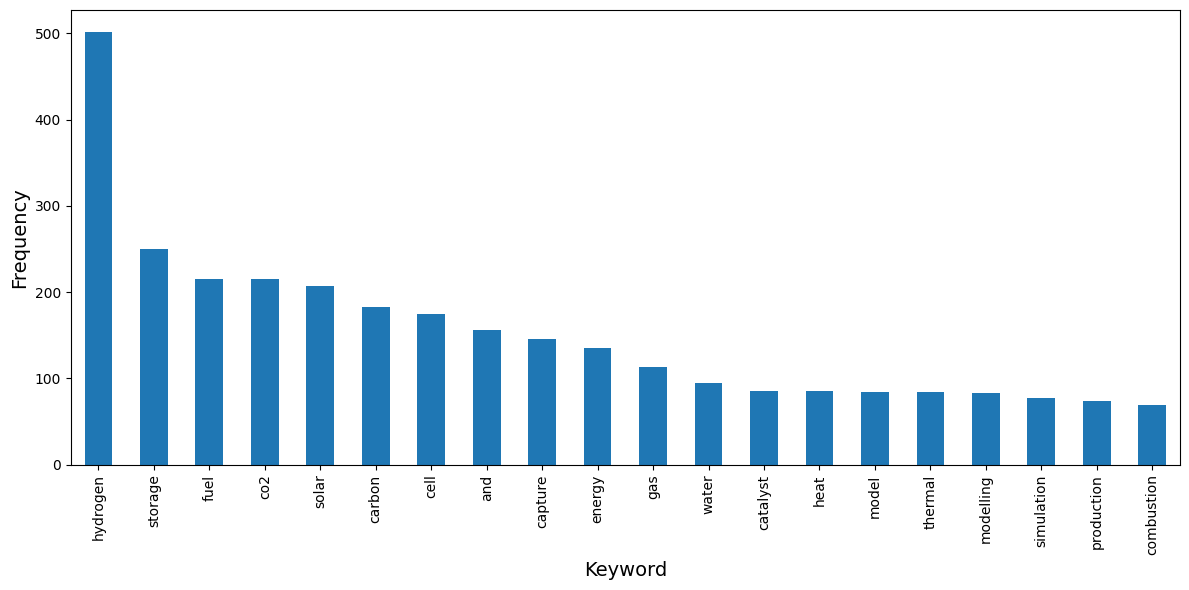

In [17]:
all_keywords = ' '.join(data['Keywords'].fillna(''))

split_keywords = all_keywords.split()
split_keywords = [word.strip(',').lower() for word in split_keywords]

keyword_frequency = pd.Series(split_keywords).value_counts()

plt.figure(figsize=(12, 6), dpi=100)
keyword_frequency.head(20).plot(kind='bar')
plt.xlabel('Keyword', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.tight_layout()
plt.savefig('most_common_keywords.png')
plt.show()

In [19]:
import ast

data['authors_genders'] = data['authors_genders'].apply(ast.literal_eval)

C:\Users\aznur\AppData\Local\Temp/ipykernel_11988/118195745.py:4: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  authors_genders_counts = data['authors_genders'].apply(pd.Series).stack().value_counts()
C:\Users\aznur\AppData\Local\Temp/ipykernel_11988/118195745.py:16: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  sns.countplot(x=data['authors_genders'].apply(pd.Series).stack(), data=data)


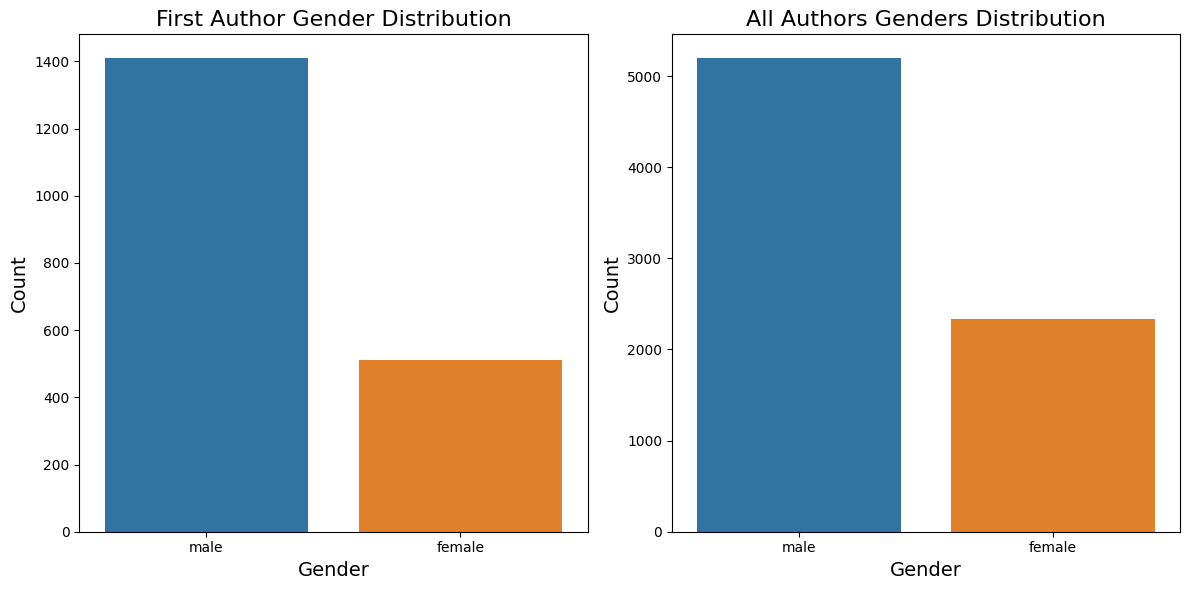

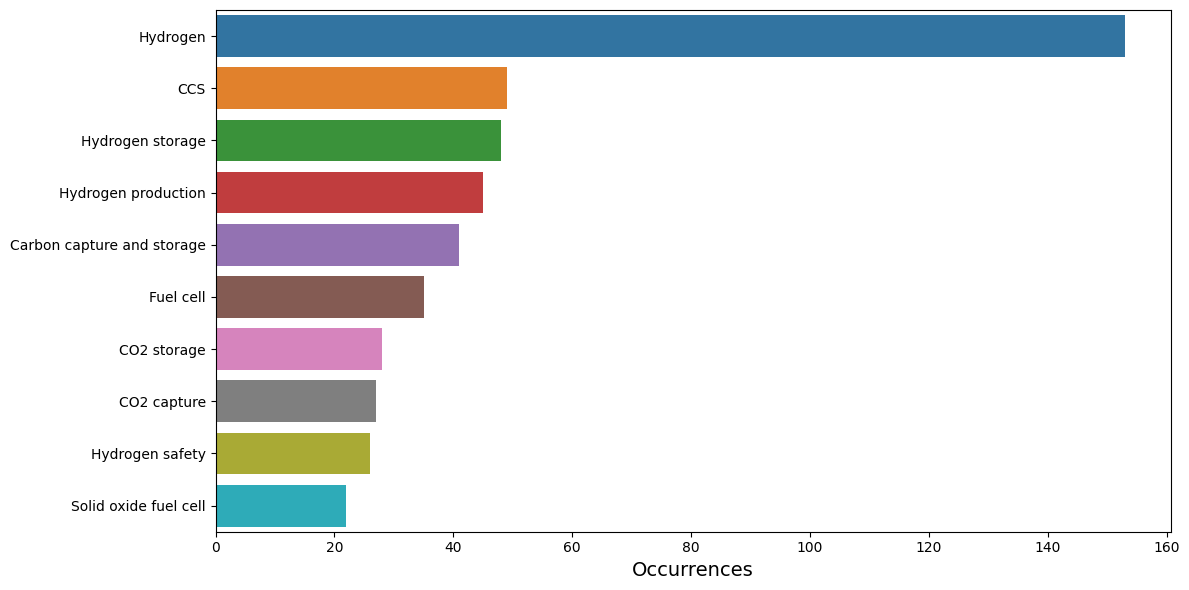

In [20]:
data['authors_genders'] = data['authors_genders'].apply(lambda genders: [gender.strip() for gender in genders])

first_author_gender_counts = data['first_author_gender'].value_counts()
authors_genders_counts = data['authors_genders'].apply(pd.Series).stack().value_counts()

all_authors_gender_counts = first_author_gender_counts.add(authors_genders_counts, fill_value=0)

plt.figure(figsize=(12, 6), dpi=100)
plt.subplot(1, 2, 1)
sns.countplot(x='first_author_gender', data=data)
plt.title('First Author Gender Distribution', fontsize=16)
plt.xlabel('Gender', fontsize=14)
plt.ylabel('Count', fontsize=14)

plt.subplot(1, 2, 2)
sns.countplot(x=data['authors_genders'].apply(pd.Series).stack(), data=data)
plt.title('All Authors Genders Distribution', fontsize=16)
plt.xlabel('Gender', fontsize=14)
plt.ylabel('Count', fontsize=14)

plt.tight_layout()
plt.savefig('authors_genders.png')
plt.show()


data = data.dropna(subset=['Keywords'])
all_keywords = [keyword.strip() for keywords_list in data['Keywords'].str.split(',') for keyword in keywords_list]
unique_keywords = list(set(all_keywords))

keyword_counts = {keyword: all_keywords.count(keyword) for keyword in unique_keywords}

sorted_keywords = sorted(keyword_counts.items(), key=lambda x: x[1], reverse=True)

top_keywords = dict(sorted_keywords[:10])
plt.figure(figsize=(12, 6), dpi=100)
sns.barplot(x=list(top_keywords.values()), y=list(top_keywords.keys()))
plt.xlabel('Occurrences', fontsize=14)
plt.tight_layout()
plt.savefig('most_10_combination.png')
plt.show()

C:\Users\aznur\AppData\Local\Temp/ipykernel_11988/1919904295.py:30: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = data.corr()


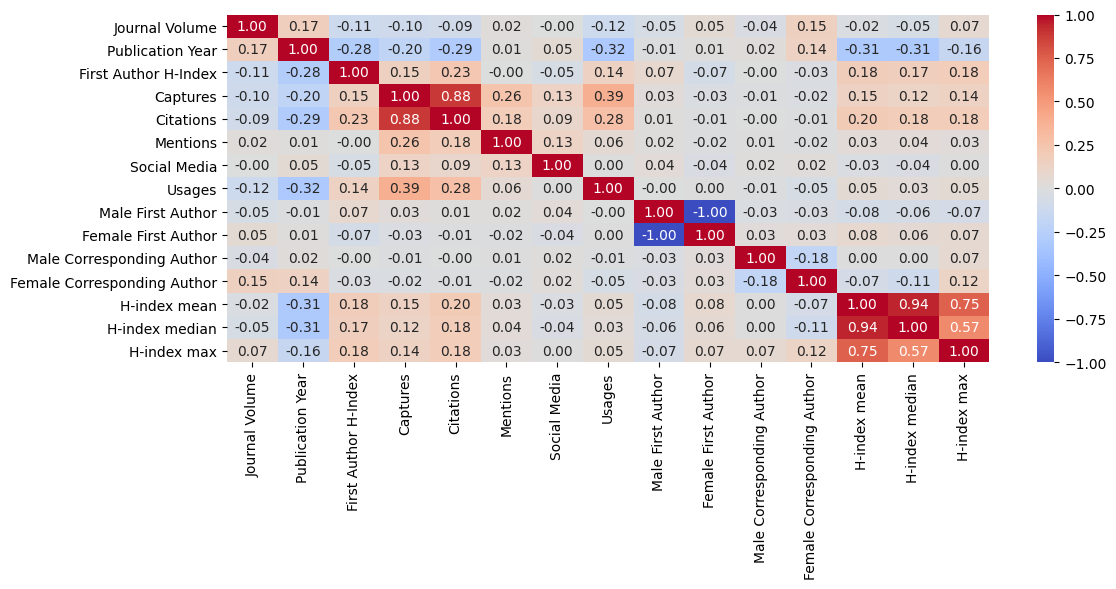

In [22]:
data['Male First Author'] = (data['first_author_gender'] == 'male').astype(int)
data['Female First Author'] = (data['first_author_gender'] == 'female').astype(int)

all_genders = set([gender for genders_list in data['authors_genders'] for gender in genders_list])
for gender in all_genders:
    data[f'{gender.title()} Corresponding Author'] = data['authors_genders'].apply(lambda genders: gender in genders).astype(int)
    
def extract_h_index_mean(h_index_list):
    if pd.notna(h_index_list):
        h_index_values = [int(h.strip()) for h in h_index_list.split(',') if h.strip().isdigit()]
        return pd.Series(h_index_values).mean()
    return None

def extract_h_index_median(h_index_list):
    if pd.notna(h_index_list):
        h_index_values = [int(h.strip()) for h in h_index_list.split(',') if h.strip().isdigit()]
        return pd.Series(h_index_values).median()
    return None

def extract_h_index_max(h_index_list):
    if pd.notna(h_index_list):
        h_index_values = [int(h.strip()) for h in h_index_list.split(',') if h.strip().isdigit()]
        return pd.Series(h_index_values).max()
    return None

data['H-index mean'] = data['Authors H-index'].apply(extract_h_index_mean)
data['H-index median'] = data['Authors H-index'].apply(extract_h_index_median)
data['H-index max'] = data['Authors H-index'].apply(extract_h_index_max)

correlation_matrix = data.corr()

columns_to_remove = ['Citations (Crossref)', 'first_author_gender_probability']
correlation_matrix = correlation_matrix.drop(columns=columns_to_remove, index=columns_to_remove)

plt.figure(figsize=(12, 6), dpi=100)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()